## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [11]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH = "/content/drive/MyDrive/ANN_LAB4/processed.cleveland.data"

## Cell 2 — Import Libraries

In [13]:
# Core data handling
import pandas as pd
import numpy as np
import random

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility (seed = 42 everywhere)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Cell 3 — Load Dataset

In [14]:
# the raw UCI file has no header, so I'm giving the column names myself
# (names taken from the UCI dataset page)
columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

# '?' is used for missing values in this file, so read it as NaN
df = pd.read_csv(DATA_PATH, header=None, names=columns, na_values="?")

# original target is 0-4 (0 = no disease, 1 to 4 = disease)
# we only need presence/absence, so anything above 0 becomes 1
df["target"] = (df["target"] > 0).astype(int)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [15]:
print("Shape:", df.shape)
print("Samples:", df.shape[0])
print("Features:", df.shape[1] - 1)   # -1 because target is not a feature

print("\nColumns:", list(df.columns))

print("\nData types:")
print(df.dtypes)

# first 5 rows
display(df.head())

# descriptive statistics
display(df.describe())

# target values
print("Target values:", df["target"].unique())

Shape: (303, 14)
Samples: 303
Features: 13

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


Target values: [0 1]


**Answers:**
- The dataset has **303 samples** and **13 features** (+ 1 target column).
- Columns: age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal, target. All features are stored as `float64`, and target is `int` after I converted it.
- Some columns look numeric but are actually categories (sex, cp, fbs, restecg, exang, slope, ca, thal), so they will be one-hot encoded later.
- From `describe()`: average age is around 54 years, cholesterol goes up to 564 which is quite high, and `ca` / `thal` have fewer counts than 303 because of missing values.
- **Target** = presence of heart disease. 0 means no disease and 1 means disease.

## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

Class counts:
target
0    164
1    139
Name: count, dtype: int64

Class percentages:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


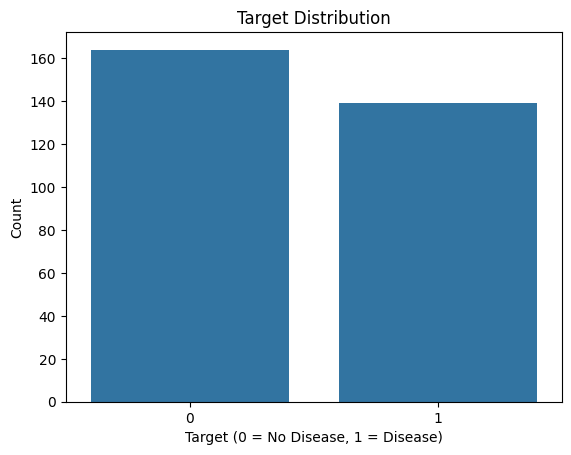

In [16]:
# count of each class
class_counts = df["target"].value_counts()
print("Class counts:")
print(class_counts)

# percentage of each class
class_percent = df["target"].value_counts(normalize=True) * 100
print("\nClass percentages:")
print(class_percent.round(2))

# plot
sns.countplot(x="target", data=df)
plt.title("Target Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Count")
plt.show()

**Observation:** There are 164 patients without disease (~54%) and 139 with disease (~46%). The difference is small, so I would say the dataset is **fairly balanced**. Because of this, accuracy is still a meaningful metric, but I will also look at precision, recall and F1. I also used `stratify=y` while splitting so both sets keep the same ratio.

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [17]:
# '?' was already converted to NaN while loading, so isnull() will catch them
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nUnique values per column:")
print(df.nunique())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Duplicate rows: 0

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Unique values per column:
age          41
sex           2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
target        2
dtype: int64


**Observation:**
- Only two columns have missing values: **`ca` (4 missing)** and **`thal` (2 missing)**. That is only 6 rows in total.
- There are no duplicate rows.
- The columns with few unique values (sex, cp, fbs, restecg, exang, slope, ca, thal) are categorical.

**Decision:** Instead of dropping rows (the dataset is already small), I will fill the missing values. Since `ca` and `thal` are both categorical, I will use the **most frequent** value. For numerical columns I will use the **median** just in case. The imputer will be fitted on the training data only (inside the pipeline).

## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

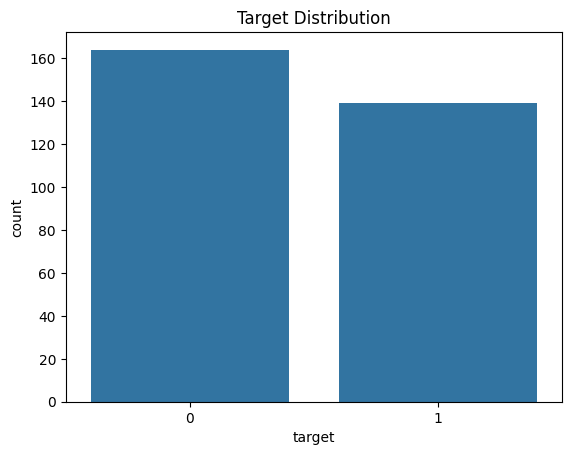

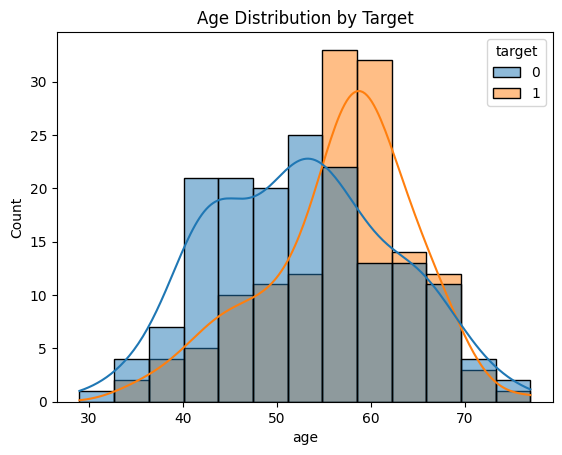

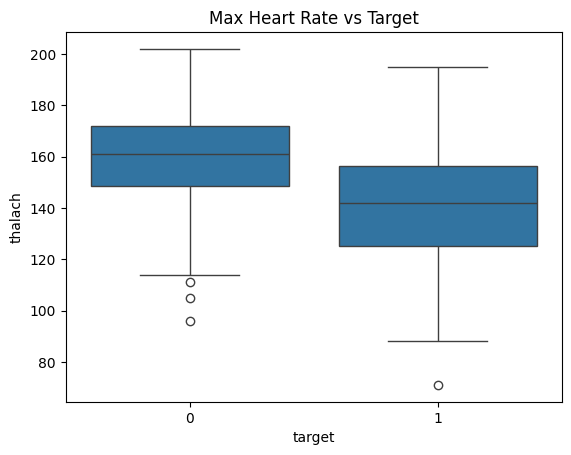

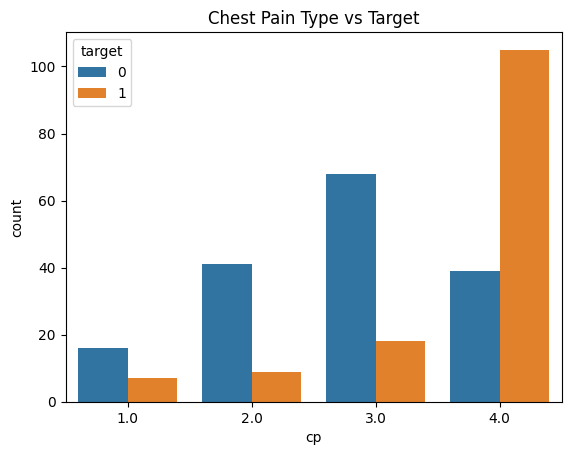

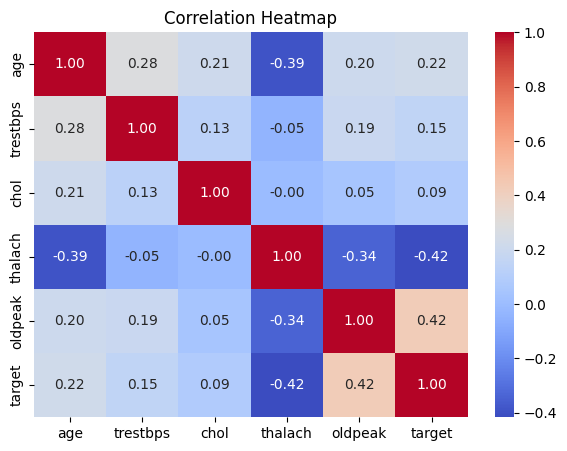

In [18]:
# numerical and categorical columns (used here and in preprocessing)
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# 1. target distribution
sns.countplot(x="target", data=df)
plt.title("Target Distribution")
plt.show()

# 2. age distribution split by target
sns.histplot(data=df, x="age", hue="target", kde=True)
plt.title("Age Distribution by Target")
plt.show()

# 3. max heart rate (thalach) vs target
sns.boxplot(x="target", y="thalach", data=df)
plt.title("Max Heart Rate vs Target")
plt.show()

# 4. chest pain type vs target
sns.countplot(x="cp", hue="target", data=df)
plt.title("Chest Pain Type vs Target")
plt.show()

# 5. correlation heatmap of numerical features (added target to see relation)
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["target"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Interpretation:**
- **Target plot:** both classes have similar counts, so the data is roughly balanced.
- **Age:** patients with heart disease are mostly a bit older (peak around 55-65), while people without disease are spread more towards younger ages.
- **Max heart rate:** patients with disease generally have a lower maximum heart rate than patients without disease.
- **Chest pain:** chest pain type 4 (asymptomatic) has a lot more disease cases than the other types, which was a bit surprising to me.
- **Heatmap:** `thalach` has a negative correlation with target (about -0.42) and `oldpeak` has a positive one (about 0.42). Cholesterol has almost no correlation with target (0.09). None of the features are very strongly correlated with each other.

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [19]:
# Define X and y
X = df.drop(columns=["target"])
y = df["target"]

# Split into train/test sets (70% train, 30% test, no validation set)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size :", X_test.shape)

# numerical columns: fill missing with median, then scale
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# categorical columns: fill missing with most frequent, then one-hot encode
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# fit only on training data so nothing leaks from the test set
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Features after preprocessing:", X_train_processed.shape[1])

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

# target as float with shape (n, 1) because I'm using BCEWithLogitsLoss
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

Train size: (212, 13)
Test size : (91, 13)
Features after preprocessing: 28


In [20]:
# Create TensorDatasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

My design (5 layers total):

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |      28 | None (just the 28 features after preprocessing) |
| Hidden 1 |      32 | ReLU |
| Hidden 2 |      16 | ReLU |
| Hidden 3 |       8 | ReLU |
| Output   |       1 | Sigmoid (applied inside `BCEWithLogitsLoss` and at prediction time) |

**Why this design:** The input is 28 because 5 numerical columns stay as they are and the 8 categorical columns turn into 23 one-hot columns. The dataset is small (only 212 training rows), so I kept the network small and reduced the neurons by half in each layer (32 → 16 → 8). ReLU is simple and works well for hidden layers. The output has 1 neuron because this is binary classification.

## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 |          28 |           32 | (28 × 32) + 32 = 896 + 32 | 928 |
| Hidden 2 |          32 |           16 | (32 × 16) + 16 = 512 + 16 | 528 |
| Hidden 3 |          16 |            8 | (16 × 8) + 8 = 128 + 8    | 136 |
| Output   |           8 |            1 | (8 × 1) + 1 = 8 + 1       |   9 |
| **Total**|             |              | 928 + 528 + 136 + 9       | **1601** |

The code in Cell 11 counts the parameters too (PyTorch doesn't have `model.summary()` like Keras, so I count them with `numel()`). It also gives **1601**, so my manual calculation matches.

## Cell 11 — Implement Neural Network in PyTorch


In [21]:
import torch
import torch.nn as nn


class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.model = nn.Sequential(
            # Input → hidden 1
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),

            # Hidden layer 2 (half the neurons)
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),

            # Hidden layer 3 (half again)
            nn.Linear(hidden_dim // 2, hidden_dim // 4),
            nn.ReLU(),

            # Output layer - no sigmoid here, BCEWithLogitsLoss does it
            nn.Linear(hidden_dim // 4, output_dim)
        )

    def forward(self, x):
        return self.model(x)


# reset seed so the starting weights are the same every run
torch.manual_seed(42)

# Create model
model = MyModel(
    input_dim=X_train_tensor.shape[1],   # 28
    hidden_dim=32,
    output_dim=1
)

print(model)

# count trainable parameters to compare with my manual calculation
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("\nTotal trainable parameters:", total_params)

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)

Total trainable parameters: 1601


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [22]:
# Binary classification with 1 output neuron -> binary cross entropy.
# BCEWithLogitsLoss = sigmoid + BCE together, which is more numerically stable
# than adding a sigmoid layer and using BCELoss separately.
loss_function = nn.BCEWithLogitsLoss()

## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [23]:
# Adam adjusts the learning rate for each weight by itself and usually
# converges faster than plain SGD, so it's a good default for a small network.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Cell 14 — Compile the Model

In [24]:
num_epochs = 50

# save losses for plotting later
history = {"train_loss": [], "test_loss": []}

for epoch in range(num_epochs):

    model.train()
    running_loss = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        # Forward pass
        outputs = model(X_batch)

        # Loss
        loss = loss_function(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    train_loss = running_loss / len(train_dataset)

    # there is no validation set, so I check loss on the test set
    # only to watch for overfitting (no weights are updated here)
    model.eval()
    test_running_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            outputs = model(X_batch)
            test_running_loss += loss_function(outputs, y_batch).item() * X_batch.size(0)

    test_loss = test_running_loss / len(test_dataset)

    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)

    # print every 5 epochs so the output isn't too long
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f}")

Epoch 5/50 | Train Loss: 0.6627 | Test Loss: 0.6581
Epoch 10/50 | Train Loss: 0.5556 | Test Loss: 0.5335
Epoch 15/50 | Train Loss: 0.3878 | Test Loss: 0.3566
Epoch 20/50 | Train Loss: 0.3339 | Test Loss: 0.3243
Epoch 25/50 | Train Loss: 0.3142 | Test Loss: 0.3266
Epoch 30/50 | Train Loss: 0.2978 | Test Loss: 0.3311
Epoch 35/50 | Train Loss: 0.2861 | Test Loss: 0.3400
Epoch 40/50 | Train Loss: 0.2761 | Test Loss: 0.3448
Epoch 45/50 | Train Loss: 0.2609 | Test Loss: 0.3519
Epoch 50/50 | Train Loss: 0.2500 | Test Loss: 0.3597


**Note:** As instructed, I used only a 70/30 train/test split with no validation set. So in the next plot, the test loss is used in place of validation loss. It is only used to look at the curves, not to tune or stop training.

## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

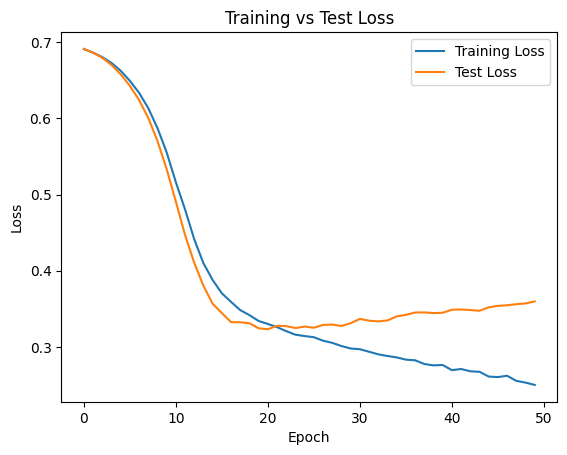

In [25]:
plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["test_loss"], label="Test Loss")
plt.title("Training vs Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

**Comment:** Both losses go down together for the first ~20 epochs. After that, the training loss keeps decreasing (to about 0.25) but the test loss slowly starts going up (from about 0.32 to 0.36). This gap means the model is starting to **overfit slightly** after around epoch 20. It is not a big gap, but training for fewer epochs, adding dropout, or using early stopping could help.

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch

# Put model in evaluation mode
model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        # Model predictions
        outputs = model(X_batch)

        # If model outputs a single logit
        probabilities = torch.sigmoid(outputs).view(-1)

        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.view(-1).cpu().numpy())

# Convert probabilities to binary predictions
threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred_nn)

precision = precision_score(
    y_true,
    y_pred_nn,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred_nn,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred_nn,
    zero_division=0
)

# Display results
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

Accuracy : 0.8242
Precision: 0.7955
Recall   : 0.8333
F1-score : 0.8140


**Result:** The neural network got around **82% accuracy** on the test set. Recall (~0.83) is a little higher than precision (~0.80), so it finds most of the disease patients but also flags some healthy people as sick. For a medical problem, higher recall is the better side to be on.

## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [27]:
# AdaBoost with 100 weak learners (decision stumps by default)
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)

# Fit on training data (same preprocessed data as the neural network)
ada_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_ada = ada_model.predict(X_test_processed)

# Calculate and display accuracy, precision, recall, and F1-score
ada_accuracy = accuracy_score(y_test, y_pred_ada)
ada_precision = precision_score(y_test, y_pred_ada, zero_division=0)
ada_recall = recall_score(y_test, y_pred_ada, zero_division=0)
ada_f1 = f1_score(y_test, y_pred_ada, zero_division=0)

print(f"Accuracy : {ada_accuracy:.4f}")
print(f"Precision: {ada_precision:.4f}")
print(f"Recall   : {ada_recall:.4f}")
print(f"F1-score : {ada_f1:.4f}")

Accuracy : 0.8571
Precision: 0.8372
Recall   : 0.8571
F1-score : 0.8471


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |   0.8242 |    0.7955 | 0.8333 |   0.8140 |
| AdaBoost       |   0.8571 |    0.8372 | 0.8571 |   0.8471 |


**Discussion:**
- **Differences:** AdaBoost did better than the neural network on all four metrics, by roughly 3 to 4 percentage points each. Both models have recall higher than precision.
- **Possible reasons:** The dataset is very small (212 training rows). Neural networks usually need a lot more data to learn well, while AdaBoost with simple decision stumps works well on small tabular data. Also AdaBoost has fewer settings to get right, while the network's result depends on epochs, learning rate, layer sizes, etc.
- **Overfitting:** Yes, the neural network shows mild overfitting. After around epoch 20 the training loss keeps dropping but the test loss goes up a bit.
- **Preprocessing impact:** Scaling was important for the neural network because features like cholesterol (~250) and oldpeak (~1) are on very different scales. One-hot encoding stopped the models from treating categories like `cp` or `thal` as ordered numbers. Filling missing values let me keep all 303 rows. Fitting the pipeline only on training data avoided data leakage.

In [28]:
# comparison table
results = pd.DataFrame({
    "Model": ["Neural Network", "AdaBoost"],
    "Accuracy": [accuracy, ada_accuracy],
    "Precision": [precision, ada_precision],
    "Recall": [recall, ada_recall],
    "F1-Score": [f1, ada_f1]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network,0.8242,0.7955,0.8333,0.8140
1,AdaBoost,0.8571,0.8372,0.8571,0.8471


## Cell 20 — Final Interpretation

In a few sentences each, discuss:
1. Whether the dataset is balanced or imbalanced
2. The important preprocessing steps you applied
3. Your neural network architecture and design choices
4. Neural network evaluation results
5. AdaBoost evaluation results
6. Comparison between the two models
7. Possible improvements for future work

**Final Interpretation**

1. **Balanced or imbalanced:** The dataset is fairly balanced, with about 54% no disease and 46% disease. I still used stratified splitting to keep the same ratio in train and test.

2. **Preprocessing:** I converted '?' to NaN and turned the 0-4 target into 0/1. Missing values in `ca` and `thal` were filled with the most frequent value (median for numerical columns). Numerical features were scaled with StandardScaler and categorical ones were one-hot encoded. I split the data 70% train / 30% test with seed 42, and fitted the preprocessing only on the training data.

3. **Architecture:** A small feed-forward network: 28 inputs → 32 → 16 → 8 → 1, with ReLU in the hidden layers and sigmoid at the output (through BCEWithLogitsLoss). It has 1601 trainable parameters, which matched my manual calculation. I used the Adam optimizer (lr = 0.001) and trained for 50 epochs with batch size 32.

4. **Neural network results:** About 82% accuracy, 0.80 precision, 0.83 recall and 0.81 F1-score. It showed slight overfitting after around 20 epochs.

5. **AdaBoost results:** About 86% accuracy, 0.84 precision, 0.86 recall and 0.85 F1-score.

6. **Comparison:** AdaBoost performed a bit better on every metric. For a small tabular dataset like this one, a boosting model seems to be the simpler and better choice than a neural network.

7. **Possible improvements:** Use early stopping or dropout to reduce overfitting, try different learning rates / epochs / layer sizes, use cross-validation instead of one split since the dataset is small, tune AdaBoost's `n_estimators` and `learning_rate`, and maybe combine the Cleveland data with the other UCI heart disease datasets (Hungary, Switzerland, VA) to get more training data.